# SGD Classifier
TF-IDF features + SGD Classifier. Trains on `train.jsonl`, monitors on `val.jsonl`, saves model to Drive.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

# ---- EDIT THIS: folder in your Google Drive that contains gujarati_fake_real_combined.jsonl ----
DATA_DIR = "/content/drive/MyDrive/RM_24DCS041_054"
MODEL_DIR = f"{DATA_DIR}/models"
import os; os.makedirs(MODEL_DIR, exist_ok=True)
SEED = 42

Mounted at /content/drive


In [2]:
import pandas as pd, numpy as np
train = pd.read_json(f"{DATA_DIR}/train.jsonl", lines=True, dtype={"news_id": str})
val   = pd.read_json(f"{DATA_DIR}/val.jsonl",   lines=True, dtype={"news_id": str})
test  = pd.read_json(f"{DATA_DIR}/test.jsonl",  lines=True, dtype={"news_id": str})
label2id = {"real": 0, "fake": 1}
id2label = {v: k for k, v in label2id.items()}
X_train, y_train = train["text"].astype(str), train["label"].map(label2id).values
X_val,   y_val   = val["text"].astype(str),   val["label"].map(label2id).values
X_test,  y_test  = test["text"].astype(str),  test["label"].map(label2id).values
print(train.shape, val.shape, test.shape)
print(train["label"].value_counts())

(13003, 3) (2786, 3)
label
fake    7238
real    5765
Name: count, dtype: int64


In [3]:
import joblib, time
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=200000, min_df=2, sublinear_tf=True)),
    ("clf", SGDClassifier(loss="modified_huber", alpha=1e-5, max_iter=50, early_stopping=True, random_state=SEED)),
])
t = time.time()
pipe.fit(X_train, y_train)
print(f"Training done in {time.time()-t:.1f}s")
pred = pipe.predict(X_val)
print("Val accuracy:", accuracy_score(y_val, pred), "| Val macro-F1:", f1_score(y_val, pred, average="macro"))
joblib.dump(pipe, f"{MODEL_DIR}/05_sgd_classifier.joblib")
print("Saved.")

Training done in 8.2s
Val accuracy: 0.8022254127781766 | Val macro-F1: 0.7999208851994717
Saved.


In [6]:
from sklearn.metrics import classification_report, recall_score, precision_score

print("\nTfidfVectorizer Parameters:")
print(f"  ngram_range: {pipe.named_steps['tfidf'].ngram_range}")
print(f"  max_features: {pipe.named_steps['tfidf'].max_features}")
print(f"  min_df: {pipe.named_steps['tfidf'].min_df}")
print(f"  sublinear_tf: {pipe.named_steps['tfidf'].sublinear_tf}")

print("\nSGDClassifier Parameters:")
print(f"  alpha: {pipe.named_steps['clf'].alpha}")
print(f"  max_iter: {pipe.named_steps['clf'].max_iter}")
print(f"  random_state: {pipe.named_steps['clf'].random_state}")

overall_accuracy = accuracy_score(y_val, pred)
overall_recall = recall_score(y_val, pred, average='macro')
overall_precision = precision_score(y_val, pred, average='macro')
overall_f1 = f1_score(y_val, pred, average='macro')

print("\nEvaluation Parameters:")
print(f"  Accuracy Score: {accuracy_score.__name__}")
print(f"  F1 Score (Macro): {f1_score.__name__} with average='macro'")

print(f"\nOverall Accuracy: {overall_accuracy:.4f}")
print(f"Overall Macro Recall: {overall_recall:.4f}")
print(f"Overall Macro Precision: {overall_precision:.4f}")
print(f"Overall Macro F1-score: {overall_f1:.4f}")

print("\nClassification Report (Validation Set):")
print(classification_report(y_val, pred, target_names=[id2label[0], id2label[1]])) # Using id2label for target names


TfidfVectorizer Parameters:
  ngram_range: (1, 2)
  max_features: 200000
  min_df: 2
  sublinear_tf: True

SGDClassifier Parameters:
  alpha: 1e-05
  max_iter: 50
  random_state: 42

Evaluation Parameters:
  Accuracy Score: accuracy_score
  F1 Score (Macro): f1_score with average='macro'

Overall Accuracy: 0.8022
Overall Macro Recall: 0.8003
Overall Macro Precision: 0.7996
Overall Macro F1-score: 0.7999

Classification Report (Validation Set):
              precision    recall  f1-score   support

        real       0.77      0.78      0.78      1235
        fake       0.83      0.82      0.82      1551

    accuracy                           0.80      2786
   macro avg       0.80      0.80      0.80      2786
weighted avg       0.80      0.80      0.80      2786



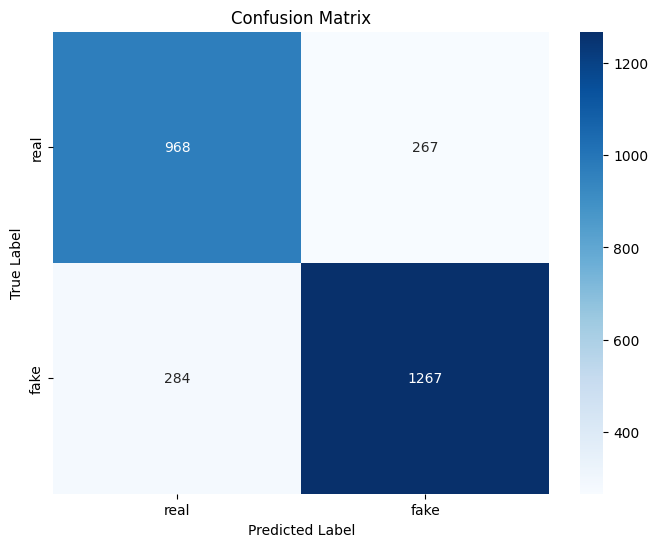

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=id2label.values(), yticklabels=id2label.values())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Final evaluation on the held-out test split (not used during fitting).
test_pred = pipe.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, test_pred))
print("Test macro precision:", precision_score(y_test, test_pred, average="macro", zero_division=0))
print("Test macro recall:", recall_score(y_test, test_pred, average="macro", zero_division=0))
print("Test macro-F1:", f1_score(y_test, test_pred, average="macro", zero_division=0))
print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=[id2label[0], id2label[1]], zero_division=0))

cm_test = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=[id2label[0], id2label[1]],
            yticklabels=[id2label[0], id2label[1]])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix (Test Set)")
plt.show()
